# **01 · ddop bakery: análisis exploratorio y preprocesamiento**

Este notebook analiza el dataset de una cadena de panaderías alemana y lo deja en el formato común que comparten los tres datasets del proyecto. Las decisiones de preprocesamiento se justifican con lo que muestra el análisis.

## **0. Contexto y fuente**

- **Origen:** ventas diarias de una cadena de panaderías en Alemania, usadas en el paper de Huber, Müller, Fleischmann y Stuckenschmidt (2019), *A data-driven newsvendor problem: From data to decision*, European Journal of Operational Research, 278(3), 904–915.
- **Publicación:** paquete `ddop` (Universidad de Würzburg), repositorio [d3group/ddop](https://github.com/d3group/ddop), con licencia BSD-3, que permite su uso académico.
- **Por qué se usa:** es la única fuente pública con muchos locales de panadería (35) y más de tres años de historia diaria, y fue construida justamente para el problema *newsvendor*, que es el que enfrenta Restocker.
- **Papel en el proyecto:** entrenamiento del modelo global. Algunos locales completos se dejarán fuera para probar el modelo con "negocios" que no vio.
- **Limitación conocida:** solo tiene 3 productos, por lo que aporta variedad de locales pero poca variedad de productos.

## **1. Descarga reproducible**

Los datos se descargan del repositorio oficial, fijando el commit para que cualquiera obtenga exactamente los mismos archivos. Se guardan en `data/raw/ddop/`, que también se versiona en el repositorio; si ya existen, no se vuelven a descargar.

In [1]:
from pathlib import Path

import pandas as pd
import requests

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "ddop"
RAW.mkdir(parents=True, exist_ok=True)

# Commit del repositorio oficial de ddop (mayo de 2024)
COMMIT = "fad8f7f319ad1afb96fe7962cd146cb423d178be"
BASE_URL = f"https://raw.githubusercontent.com/d3group/ddop/{COMMIT}/ddop/datasets"
FILES = {
    "bakery_data.csv": "data/bakery_data.csv",
    "bakery_target.csv": "data/bakery_target.csv",
    "bakery.rst": "descr/bakery.rst",
}

for name, remote in FILES.items():
    path = RAW / name
    if not path.exists():
        response = requests.get(f"{BASE_URL}/{remote}", timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    print(f"{name}: {path.stat().st_size / 1024:,.0f} KB")

bakery_data.csv: 6,166 KB
bakery_target.csv: 642 KB
bakery.rst: 1 KB


## **2. Composición**

El dataset viene en dos archivos que se leen juntos, fila por fila: `bakery_data.csv` trae las variables y `bakery_target.csv` trae la demanda. Cada fila es **un producto, en un local, en un día**.

- `date`: el día.
- `weekday`, `month`, `year`: día de la semana, mes y año en texto, derivados de la fecha.
- `store`: número del local (35 locales).
- `product`: número del producto; solo hay tres (101, 109 y 110) y no tienen nombre.
- `demand`: unidades vendidas ese día. **Es la variable que se quiere predecir.**
- `is_holiday`: si el día es feriado nacional en Alemania.
- `is_holiday_next2days`: si hay un feriado en los próximos dos días.
- `is_schoolholiday`: si son vacaciones escolares.
- `rain`: lluvia del día.
- `temperature`: temperatura promedio del día, en °C.
- `promotion_currentweek`: si hubo promoción esa semana.
- `promotion_lastweek`: si hubo promoción la semana anterior.

In [2]:
features = pd.read_csv(RAW / "bakery_data.csv", parse_dates=["date"])
target = pd.read_csv(RAW / "bakery_target.csv")
df = features.assign(demand=target["demand"])

df.head()

,date,weekday,month,year,is_schoolholiday,is_holiday,is_holiday_next2days,store,product,rain,temperature,promotion_currentweek,promotion_lastweek,demand
0,2016-01-02,FRI,JAN,2016,1,0,0,2,101,11.9,2.1,0,0,254.0
1,2016-01-03,SAT,JAN,2016,1,0,0,2,101,4.1,2.6,0,0,538.0
2,2016-01-04,SUN,JAN,2016,1,0,1,2,101,7.9,3.2,0,0,132.0
3,2016-01-05,MON,JAN,2016,1,0,1,2,101,3.5,3.1,0,0,154.0
4,2016-01-06,TUE,JAN,2016,1,1,0,2,101,0.1,4.1,0,0,331.0


In [3]:
df.dtypes

date                     datetime64[us]
weekday                             str
month                               str
year                              int64
is_schoolholiday                  int64
is_holiday                        int64
is_holiday_next2days              int64
store                             int64
product                           int64
rain                            float64
temperature                     float64
promotion_currentweek             int64
promotion_lastweek                int64
demand                          float64
dtype: object

In [4]:
n_series = df.groupby(["store", "product"]).ngroups
n_days = df["date"].nunique()

print(f"Filas: {len(df):,}")
print(f"Locales: {df['store'].nunique()} | Productos: {df['product'].nunique()} | Series (local × producto): {n_series}")
print(f"Rango: {df['date'].min().date()} a {df['date'].max().date()} ({n_days:,} días)")
print(f"Filas por serie: {len(df) // n_series:,}")

Filas: 127,575
Locales: 35 | Productos: 3 | Series (local × producto): 105
Rango: 2016-01-02 a 2019-04-30 (1,215 días)
Filas por serie: 1,215


## **3. Calidad**

El dataset no tiene valores nulos ni negativos, no hay filas repetidas para un mismo local, producto y día, y todas las series tienen la misma cantidad de días. Solo 42 valores de demanda (0.03 %) tienen decimales, la mayoría medias unidades como 437.5. La celda siguiente lo comprueba.

In [5]:
checks = {
    "Valores nulos": int(df.isna().sum().sum()),
    "Demanda negativa": int((df["demand"] < 0).sum()),
    "Demanda con decimales": int((df["demand"] % 1 != 0).sum()),
    "Filas repetidas (local, producto, día)": int(df.duplicated(["store", "product", "date"]).sum()),
    "Series con días faltantes": int((df.groupby(["store", "product"]).size() != n_days).sum()),
}
pd.Series(checks, name="Cantidad").to_frame()

,Cantidad
Valores nulos,0
Demanda negativa,0
Demanda con decimales,42
"Filas repetidas (local, producto, día)",0
Series con días faltantes,0


Los 42 valores con decimales se redondean al entero más cercano, porque las unidades vendidas son enteras y representan apenas el 0.03 % de los datos.

In [6]:
decimals = df["demand"] % 1 != 0
df.loc[decimals, ["date", "store", "product", "demand"]].head()

,date,store,product,demand
134,2016-05-15,2,101,1155.500
7096,2018-10-19,3,110,56.063
11923,2018-09-16,5,101,232.990
14353,2018-09-16,5,110,73.990
18885,2017-10-23,19,101,437.500


In [7]:
df["demand"] = df["demand"].round().astype(int)
print(f"Valores redondeados: {int(decimals.sum())} | Demanda con decimales ahora: {int((df['demand'] % 1 != 0).sum())}")

Valores redondeados: 42 | Demanda con decimales ahora: 0


Lo que sí hay que revisar es la columna `weekday`: para el 2 de enero de 2016, que fue sábado, dice `FRI`. La comparamos contra el día real que corresponde a cada fecha.

In [8]:
days = df[["date", "weekday"]].drop_duplicates("date").head(7)
days.assign(dia_real=days["date"].dt.day_name())

,date,weekday,dia_real
0,2016-01-02,FRI,Saturday
1,2016-01-03,SAT,Sunday
2,2016-01-04,SUN,Monday
3,2016-01-05,MON,Tuesday
4,2016-01-06,TUE,Wednesday
5,2016-01-07,WED,Thursday
6,2016-01-08,THU,Friday


Para saber si el error está en la etiqueta o en la fecha, revisamos los feriados marcados en el dataset: si caen en su fecha real del calendario alemán, la fecha es la correcta.

In [9]:
holidays = df.loc[df["is_holiday"] == 1, ["date"]].drop_duplicates().head(10)
holidays.assign(dia_real=holidays["date"].dt.day_name())

,date,dia_real
4,2016-01-06,Wednesday
83,2016-03-25,Friday
85,2016-03-27,Sunday
86,2016-03-28,Monday
120,2016-05-01,Sunday
124,2016-05-05,Thursday
134,2016-05-15,Sunday
135,2016-05-16,Monday
145,2016-05-26,Thursday
275,2016-10-03,Monday


Los feriados caen en su día real (el 25 de marzo de 2016, Viernes Santo, es viernes; el 3 de octubre, Día de la Unidad Alemana, es lunes), así que **la fecha es correcta y la etiqueta `weekday` está corrida un día**. Por eso no se usan `weekday`, `month` ni `year`: el día de la semana se calcula a partir de `date` (0 = lunes, 6 = domingo).

In [10]:
df = df.drop(columns=["weekday", "month", "year"])
df["day_of_week"] = df["date"].dt.day_of_week

df[["date", "day_of_week"]].drop_duplicates("date").head(7)

,date,day_of_week
0,2016-01-02,5
1,2016-01-03,6
2,2016-01-04,0
3,2016-01-05,1
4,2016-01-06,2
5,2016-01-07,3
6,2016-01-08,4


## **4. Ceros y cierres**

Un cero puede significar dos cosas distintas: que el local abrió y ese producto no se vendió, o que el local estaba cerrado. La diferencia importa, porque si los cierres se tratan como "demanda 0", el modelo aprendería que ciertos días no se vende nada cuando en realidad no se abrió.

In [11]:
zeros = df[df["demand"] == 0]
print(f"Ceros: {len(zeros):,} de {len(df):,} filas ({len(zeros) / len(df):.1%})")

zeros["date"].dt.day_name().value_counts().rename("Ceros por día de la semana").to_frame()

Ceros: 15,399 de 127,575 filas (12.1%)


,Ceros por día de la semana
date,
Sunday,7230
Monday,1611
Saturday,1446
Tuesday,1340
Thursday,1338
Friday,1317
Wednesday,1117


Los domingos concentran casi la mitad de los ceros. Si un local no vendió **ninguno** de sus productos en todo el día, lo más razonable es que estaba cerrado. Con esa regla se marca cada día de cada local como abierto o cerrado (`is_open`).

In [12]:
store_day = df.groupby(["store", "date"])["demand"].sum().rename("store_sales").reset_index()
store_day["is_open"] = store_day["store_sales"] > 0
df = df.merge(store_day[["store", "date", "is_open"]], on=["store", "date"])

closed_zeros = int(((df["demand"] == 0) & ~df["is_open"]).sum())
open_zeros = int(((df["demand"] == 0) & df["is_open"]).sum())
print(f"Días-local cerrados: {int((~store_day['is_open']).sum()):,} de {len(store_day):,}")
print(f"Ceros explicados por cierre: {closed_zeros:,} ({closed_zeros / len(zeros):.0%})")
print(f"Ceros con el local abierto: {open_zeros:,}")

Días-local cerrados: 4,897 de 42,525
Ceros explicados por cierre: 14,691 (95%)
Ceros con el local abierto: 708


In [13]:
sunday_closed = (
    store_day[store_day["date"].dt.day_of_week == 6]
    .groupby("store")["is_open"]
    .apply(lambda s: (~s).mean())
    .rename("domingos_cerrados")
)
pd.cut(sunday_closed, [-0.01, 0.1, 0.5, 0.9, 1.0], labels=["Casi nunca", "A veces", "Casi siempre", "Siempre"]).value_counts().sort_index().rename("Locales").to_frame()

,Locales
domingos_cerrados,
Casi nunca,21
A veces,1
Casi siempre,1
Siempre,12


In [14]:
closed = store_day[~store_day["is_open"]].merge(df[["store", "date", "is_holiday"]].drop_duplicates(), on=["store", "date"])
print(f"Cierres en feriado: {int(closed['is_holiday'].sum()):,} de {len(closed):,}")

Cierres en feriado: 1,069 de 4,897


**Conclusión:** el 95 % de los ceros corresponde a días en que el local estaba cerrado, sobre todo domingos y feriados. Esos días se marcan con `is_open = False`: se mantienen en los datos para no romper la secuencia de días, pero no cuentan como demanda 0 al medir el error del modelo. Los ceros con el local abierto se quedan como ceros reales.

## **5. Distribuciones y escala**

Esta sección usa solo los días con el local abierto, porque los cierres ya se separaron en la sección anterior. Busca responder qué tan distintas son las series entre sí y si hay valores atípicos.

In [15]:
import matplotlib.pyplot as plt

open_days = df[df["is_open"]]
open_days.groupby("product")["demand"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
product,,,,,,,,
101,37628.0,233.3,190.3,0.0,105.0,180.0,306.0,1783.0
109,37628.0,36.7,29.7,0.0,16.0,27.0,49.0,253.0
110,37628.0,69.2,42.4,0.0,37.0,59.0,95.0,344.0


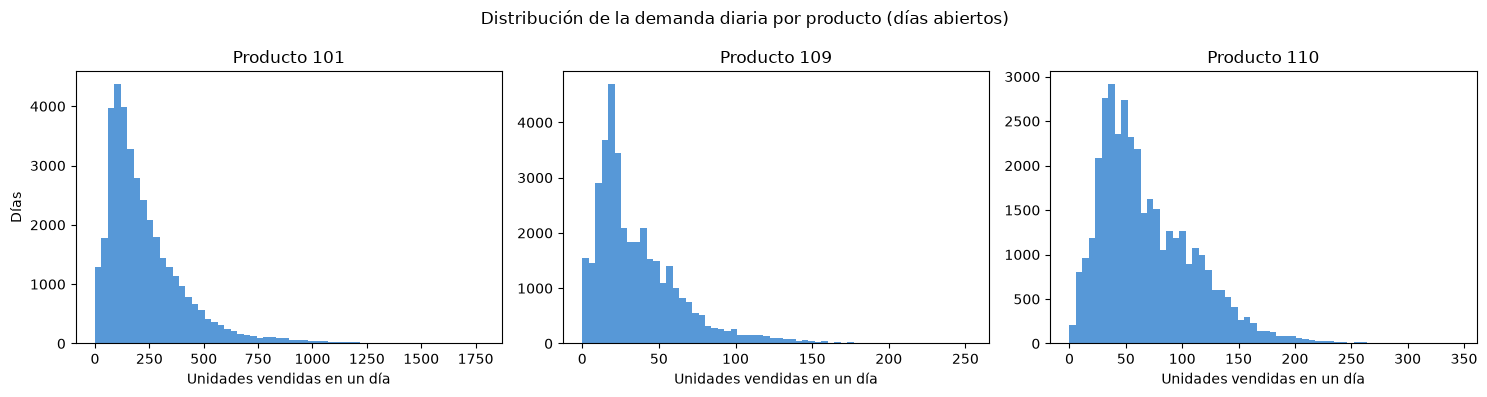

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (product, group) in zip(axes, open_days.groupby("product")):
    ax.hist(group["demand"], bins=60, color="#5798d7")
    ax.set_title(f"Producto {product}")
    ax.set_xlabel("Unidades vendidas en un día")
axes[0].set_ylabel("Días")
fig.suptitle("Distribución de la demanda diaria por producto (días abiertos)")
plt.tight_layout()
plt.show()

Los tres productos venden en escalas muy distintas, y dentro de un mismo producto también cambia mucho de un local a otro. La siguiente celda compara la venta promedio de cada serie (local × producto).

In [17]:
series_mean = open_days.groupby(["product", "store"])["demand"].mean()
series_mean.groupby("product").agg(["min", "median", "max"]).round(1).assign(
    max_entre_min=lambda t: (t["max"] / t["min"]).round(1)
)

,min,median,max,max_entre_min
product,,,,
101,3.6,163.3,668.3,185.6
109,1.3,27.5,85.3,65.6
110,9.9,57.4,132.3,13.4


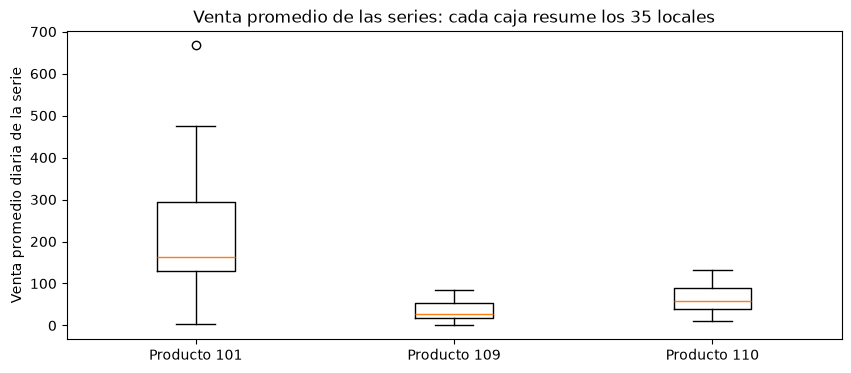

In [18]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([series_mean.loc[p] for p in series_mean.index.levels[0]], tick_labels=[f"Producto {p}" for p in series_mean.index.levels[0]])
ax.set_ylabel("Venta promedio diaria de la serie")
ax.set_title("Venta promedio de las series: cada caja resume los 35 locales")
plt.show()

Para detectar valores atípicos, cada venta se compara contra la mediana de su propia serie, porque un mismo número puede ser normal en un local grande y extremo en uno pequeño.

In [19]:
ratio = open_days["demand"] / open_days.groupby(["store", "product"])["demand"].transform("median")
for k in [3, 5, 10]:
    print(f"Días con venta mayor a {k} veces la mediana de su serie: {int((ratio > k).sum()):,} ({(ratio > k).mean():.2%})")

open_days.assign(veces_mediana=ratio.round(1)).nlargest(8, "veces_mediana")[
    ["date", "store", "product", "demand", "veces_mediana", "is_holiday", "promotion_currentweek"]
]

Días con venta mayor a 3 veces la mediana de su serie: 1,226 (1.09%)
Días con venta mayor a 5 veces la mediana de su serie: 64 (0.06%)
Días con venta mayor a 10 veces la mediana de su serie: 3 (0.00%)


,date,store,product,demand,veces_mediana,is_holiday,promotion_currentweek
8390,2019-01-06,4,101,56,18.7,1,0
8488,2019-04-14,4,101,51,17.0,0,1
134,2016-05-15,2,101,1156,10.3,1,0
9572,2018-12-04,4,109,9,9.0,0,0
7417,2016-05-08,4,101,26,8.7,0,0
869,2018-05-20,2,101,925,8.3,1,0
519,2017-06-04,2,101,923,8.2,1,0
1349,2016-05-15,2,109,136,8.0,1,1


**Conclusiones de la sección:**

- **Escala:** dentro de un mismo producto, un local vende hasta 186 veces más que otro. Por eso, antes de entrenar, cada serie se normalizará por su propia escala; si no, el modelo se concentraría en acertar las series grandes.
- **Valores atípicos:** no se eliminan. Son muy pocos (64 días superan 5 veces la mediana de su serie) y los más extremos coinciden con feriados reales, como el domingo de Pentecostés de 2016.
- **Local 4:** se conserva. Vende entre 1 y 11 unidades al día durante los tres años, una escala parecida a la de un negocio pequeño como Sakura.

## **6. Patrones temporales**

Para comparar series de escalas distintas, cada venta se divide entre el promedio de su serie en días abiertos. Así, un valor de 1.3 significa "30 % más de lo normal para esa serie", sin importar si el local vende 3 o 300 unidades al día.

In [20]:
open_days = open_days.assign(
    relative=open_days["demand"] / open_days.groupby(["store", "product"])["demand"].transform("mean")
)
day_names = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]

weekly = open_days.groupby(["day_of_week", "product"])["relative"].mean().unstack()
weekly.index = day_names
weekly.round(2)

product,101,109,110
Lun,0.86,0.88,0.96
Mar,0.83,0.83,0.94
Mié,0.84,0.84,0.95
Jue,0.85,0.85,0.96
Vie,1.00,0.91,1.01
Sáb,1.34,1.37,1.15
Dom,1.43,1.48,1.05


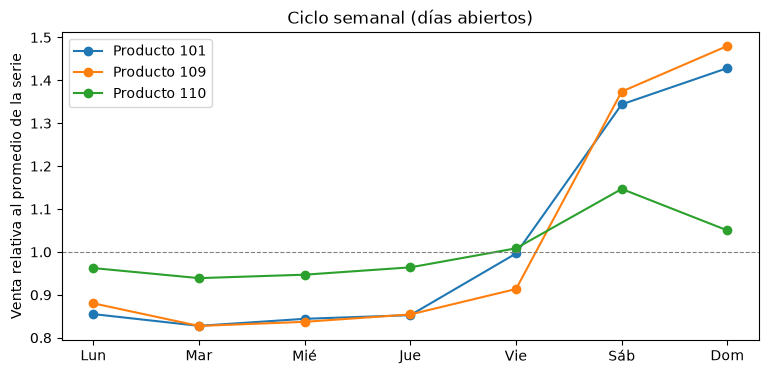

In [21]:
fig, ax = plt.subplots(figsize=(9, 4))
for product in weekly.columns:
    ax.plot(weekly.index, weekly[product], marker="o", label=f"Producto {product}")
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Ciclo semanal (días abiertos)")
ax.legend()
plt.show()

El ciclo anual se revisa igual, promediando la venta relativa de cada mes.

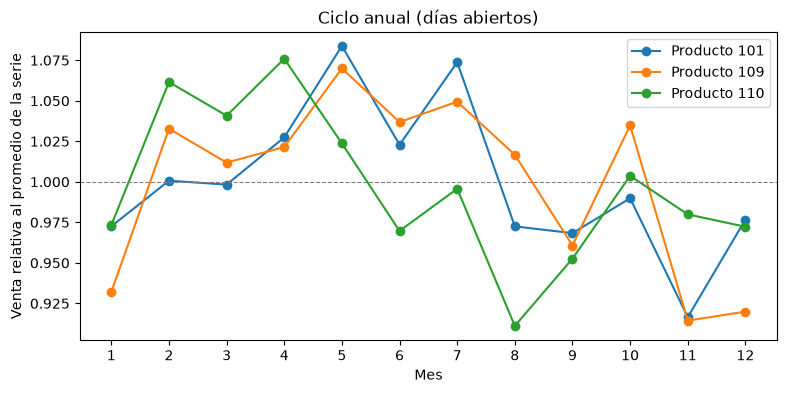

In [22]:
monthly = open_days.groupby([open_days["date"].dt.month, "product"])["relative"].mean().unstack()
fig, ax = plt.subplots(figsize=(9, 4))
for product in monthly.columns:
    ax.plot(monthly.index, monthly[product], marker="o", label=f"Producto {product}")
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Mes")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Ciclo anual (días abiertos)")
ax.legend()
plt.show()

Para ver si las ventas crecen o caen con los años, se promedia la venta relativa por trimestre.

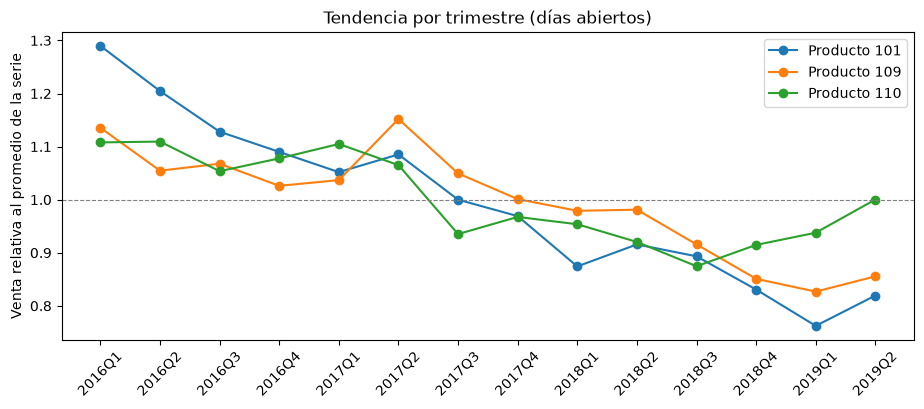

In [23]:
quarterly = open_days.groupby([open_days["date"].dt.to_period("Q"), "product"])["relative"].mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4))
for product in quarterly.columns:
    ax.plot(quarterly.index.astype(str), quarterly[product], marker="o", label=f"Producto {product}")
ax.axhline(1, color="gray", linewidth=0.8, linestyle="--")
ax.set_ylabel("Venta relativa al promedio de la serie")
ax.set_title("Tendencia por trimestre (días abiertos)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
plt.show()

Por último, la autocorrelación indica qué tanto se parece la venta de hoy a la de hace *k* días. Esto sirve para decidir cuántos días hacia atrás debe mirar el modelo. Se calcula por serie, con los cierres como valores faltantes, y se promedia.

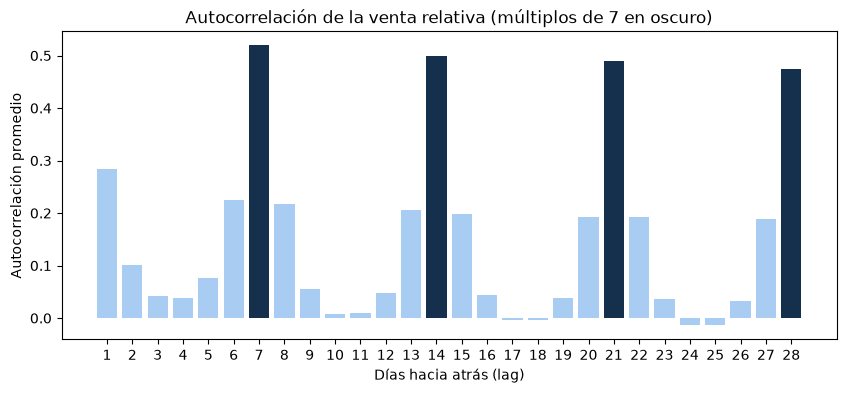

In [24]:
def series_autocorr(group, lags):
    s = group.set_index("date")["relative_all"]
    return pd.Series({lag: s.autocorr(lag) for lag in lags})

lags = range(1, 29)
full = df.merge(open_days[["store", "product", "date", "relative"]], on=["store", "product", "date"], how="left")
full = full.rename(columns={"relative": "relative_all"}).sort_values("date")
acf = full.groupby(["store", "product"]).apply(series_autocorr, lags=lags).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(acf.index, acf.values, color=["#14304d" if lag % 7 == 0 else "#a9ccf2" for lag in acf.index])
ax.set_xticks(list(lags))
ax.set_xlabel("Días hacia atrás (lag)")
ax.set_ylabel("Autocorrelación promedio")
ax.set_title("Autocorrelación de la venta relativa (múltiplos de 7 en oscuro)")
plt.show()

**Conclusiones de la sección:**

- **Ciclo semanal:** es el patrón dominante. El fin de semana vende entre 35 y 50 % más que entre semana, y la autocorrelación tiene sus picos exactamente cada 7 días (7, 14, 21 y 28). Por eso el modelo debe mirar hacia atrás en múltiplos de 7 días (14 o 28). Si además conviene darle el día de la semana como variable se decidirá con una iteración del entrenamiento, porque The Bread Basket (la prueba) tiene su pico el sábado y no el domingo (ver notebook 03).
- **Ciclo anual:** es débil (entre −9 % y +8 % según el mes) y propio de Alemania, así que no se modela; incluirlo solo agregaría ruido y sesgaría el modelo a un calendario que no es el de Guatemala.
- **Tendencia:** las ventas caen cerca de 35 % entre 2016 y 2019. Por eso cada ventana se normalizará con el promedio de sus propios días de entrada y no con el promedio de toda la serie, que además incluiría días futuros y causaría fuga de información. Esa misma regla aplica a cualquier estadística (promedio, desviación, mínimo o máximo): se calcula solo con los datos de la ventana o de la partición de entrenamiento.

## **7. Variables externas**

Además de la fecha, ddop trae feriados, vacaciones escolares, promociones y clima. Para medir su efecto sin confundirlo con el ciclo semanal, cada venta relativa se compara contra lo esperado para ese producto en ese día de la semana: un efecto de 1.20 significa que, con la variable activa, se vende 20 % más de lo normal para ese día.

In [25]:
expected = open_days.groupby(["product", "day_of_week"])["relative"].transform("mean")
open_days = open_days.assign(vs_expected=open_days["relative"] / expected)

flags = ["is_holiday", "is_holiday_next2days", "is_schoolholiday", "promotion_currentweek", "promotion_lastweek"]
effects = pd.DataFrame({
    flag: {
        "Días con la variable activa": int((open_days[flag] == 1).sum()),
        "Efecto (activa)": open_days.loc[open_days[flag] == 1, "vs_expected"].mean(),
        "Efecto (inactiva)": open_days.loc[open_days[flag] == 0, "vs_expected"].mean(),
    }
    for flag in flags
}).T
effects.round(2)

,Días con la variable activa,Efecto (activa),Efecto (inactiva)
is_holiday,1728.0,1.33,0.99
is_holiday_next2days,6921.0,1.13,0.99
is_schoolholiday,27081.0,1.01,1.00
promotion_currentweek,11087.0,1.17,0.98
promotion_lastweek,11002.0,0.99,1.00


Para el clima, la correlación indica si los días más lluviosos o calurosos venden más o menos de lo esperado.

In [26]:
open_days[["vs_expected", "rain", "temperature"]].corr().loc[["rain", "temperature"], "vs_expected"].round(3).rename("Correlación con la venta").to_frame()

,Correlación con la venta
rain,-0.007
temperature,0.006


Una variable solo le sirve al modelo si existe en **todos** los datasets y si el negocio la conocería al momento de predecir. La siguiente tabla lo resume:

| Variable | ddop | French Bakery | The Bread Basket | Sakura |
| :- | :-: | :-: | :-: | :-: |
| Feriados | Sí | Se puede construir con el calendario de Francia | Se puede construir con el calendario de Reino Unido | Se puede construir con el calendario de Guatemala |
| Vacaciones escolares | Sí | No | No | No |
| Promociones | Sí | No | No | No |
| Lluvia y temperatura | Sí | No | No | Habría que obtenerlo de un servicio externo |

**Conclusiones de la sección:**

- **Feriados:** se conservan `is_holiday` (en feriado se vende 33 % más) e `is_holiday_next2days` (13 % más en los días previos). Para que el modelo no dependa del calendario alemán, en cada dataset se construirán con el calendario de su propio país, y en Sakura con el de Guatemala.
- **Vacaciones escolares y clima:** se descartan, porque no tienen efecto en la venta (efecto de 1.01 y correlaciones cercanas a cero) y solo existen en ddop.
- **Promociones:** se descartan, aunque la promoción de la semana sí aumenta la venta en 17 %. Hay dos razones:
  - **Técnica:** solo ddop registra promociones. En French Bakery y The Bread Basket no sabemos si hubo, y llenar ese dato con "no hubo" sería inventarlo. Quitarla mantiene la misma estructura para todos los datasets y permite evaluar el modelo igual en todos.
  - **De negocio:** el efecto depende mucho del tipo de promoción. Un 2x1 no se comporta igual que vender un grupo de postres a un quetzal durante dos horas, así que lo aprendido de las promociones de una panadería alemana no se trasladaría a otro negocio.

  En Restocker, el pronóstico mostrará un aviso de que no considera promociones.

## **8. Decisiones de preprocesamiento**

| # | Decisión | Justificación | Sección |
| :- | :- | :- | :- |
| 1 | El día de la semana se calcula a partir de `date`; no se usan `weekday`, `month` ni `year`. | La etiqueta `weekday` está corrida un día, mientras que la fecha coincide con los feriados reales. | 3 |
| 2 | Los 42 valores de demanda con decimales se redondean al entero más cercano. | Las unidades vendidas son enteras y los casos son el 0.03 % de los datos. | 3 |
| 3 | Un local está cerrado un día si ninguno de sus productos vendió; esos días quedan con `is_open = False`. | El 95 % de los ceros corresponde a cierres. Se mantienen para no romper la secuencia de días, pero no cuentan como demanda 0 al medir el error. | 4 |
| 4 | Los ceros con el local abierto se mantienen como ceros reales. | Son días en que el local abrió y ese producto no se vendió. | 4 |
| 5 | No se eliminan valores atípicos. | Son muy pocos y coinciden con feriados reales. | 5 |
| 6 | Se conservan todos los locales, incluido el local 4. | Su escala pequeña se parece a la de un negocio como Sakura. | 5 |
| 7 | Cada ventana se normalizará con el promedio de sus propios días de entrada. | La escala cambia mucho entre series y las ventas caen con los años; usar estadísticas de toda la serie causaría fuga de información. Se aplica al preparar el entrenamiento. | 5 y 6 |
| 8 | No se modela el ciclo anual. | Es débil y propio de Alemania. | 6 |
| 9 | Se conservan los feriados como "es feriado" y "feriado en los próximos días", construidos con el calendario de cada país. | Tienen efecto (+33 % y +13 %) y se pueden construir para cualquier negocio. Se agregan en el notebook de unificación, con la misma lógica para los tres datasets. | 7 |
| 10 | Se descartan vacaciones escolares, clima y promociones. | No tienen efecto o solo existen en ddop; el efecto de una promoción depende del tipo de promoción de cada negocio. | 7 |

## **9. Exportar al formato común**

Los tres datasets terminan con la misma estructura, una fila por local, producto y día:

- `dataset`: de qué fuente viene.
- `store_id`: identificador del local.
- `product_id`: identificador del producto.
- `date`: el día.
- `sales`: unidades vendidas.
- `is_open`: si el local abrió ese día.

Los identificadores sirven para separar las series y dividir los datos; no entran al modelo como variables.

In [27]:
processed = pd.DataFrame({
    "dataset": "ddop",
    "store_id": "ddop_" + df["store"].astype(str),
    "product_id": "ddop_" + df["product"].astype(str),
    "date": df["date"],
    "sales": df["demand"],
    "is_open": df["is_open"],
}).sort_values(["store_id", "product_id", "date"]).reset_index(drop=True)

OUT = ROOT / "data" / "processed" / "ddop_bakery.parquet"
processed.to_parquet(OUT, index=False)

print(f"Guardado en {OUT.relative_to(ROOT)} ({OUT.stat().st_size / 1024:,.0f} KB)")
print(f"Filas: {len(processed):,} | Series: {processed.groupby(['store_id', 'product_id']).ngroups} | Días cerrados: {int((~processed['is_open']).sum()):,} filas")
processed.head()

Guardado en data/processed/ddop_bakery.parquet (344 KB)
Filas: 127,575 | Series: 105 | Días cerrados: 14,691 filas


,dataset,store_id,product_id,date,sales,is_open
0,ddop,ddop_17,ddop_101,2016-01-02,400,True
1,ddop,ddop_17,ddop_101,2016-01-03,263,True
2,ddop,ddop_17,ddop_101,2016-01-04,258,True
3,ddop,ddop_17,ddop_101,2016-01-05,308,True
4,ddop,ddop_17,ddop_101,2016-01-06,148,True
